<a href="https://colab.research.google.com/github/yashrajsharan18/Machine-Learning/blob/main/unit_3_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
sns.set_style('whitegrid')

In [ ]:
data = fetch_openml(data_id=1104, as_frame=True, parser='auto')
X = data.data.astype(float)
y, class_names = pd.factorize(data.target.astype(str))

print('Shape (samples, genes):', X.shape)
print('Classes:', list(class_names), '| Counts:', np.bincount(y))
print('Missing values:', X.isna().sum().sum())

X = X.loc[:, X.std() > 0]          # drop constant genes
print('Shape after removing constant genes:', X.shape)

Shape (samples, genes): (72, 7129)
Classes: ['ALL', 'AML'] | Counts: [47 25]
Missing values: 0
Shape after removing constant genes: (72, 7129)


In [ ]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(X_scaled)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
print('Max possible components:', len(evr))

thresholds = {}
for t in [0.80, 0.90, 0.95, 0.99]:
    thresholds[t] = int(np.argmax(cum >= t) + 1)
    print(f'{int(t*100)}% variance -> {thresholds[t]} components')

Max possible components: 72
80% variance -> 37 components
90% variance -> 51 components
95% variance -> 60 components
99% variance -> 69 components


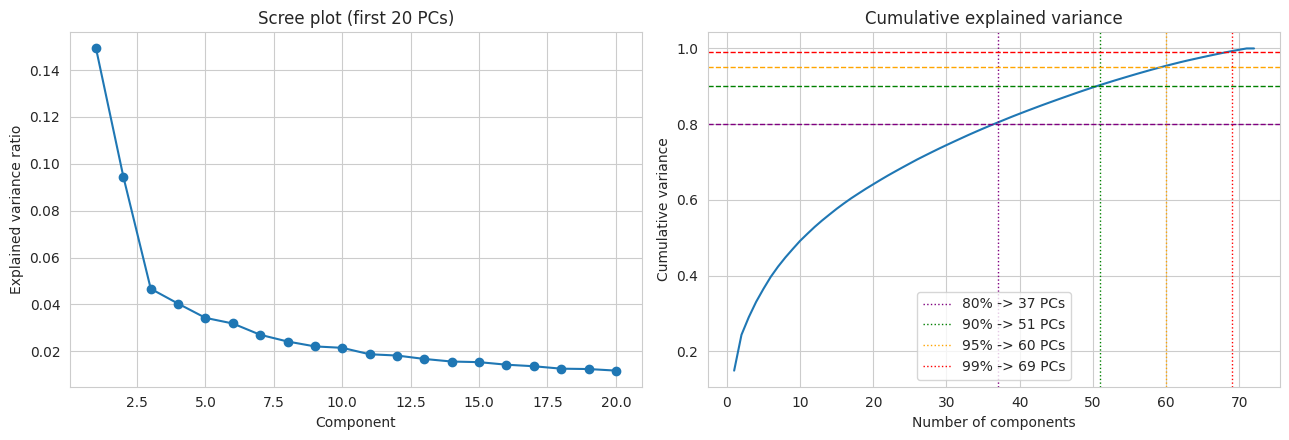

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(range(1, 21), evr[:20], 'o-')
ax[0].set(title='Scree plot (first 20 PCs)', xlabel='Component', ylabel='Explained variance ratio')

ax[1].plot(range(1, len(cum)+1), cum)
for t, c in [(0.80,'purple'), (0.90,'green'), (0.95,'orange'), (0.99,'red')]:
    k = thresholds[t]
    ax[1].axhline(t, color=c, ls='--', lw=1)
    ax[1].axvline(k, color=c, ls=':', lw=1, label=f'{int(t*100)}% -> {k} PCs')
ax[1].set(title='Cumulative explained variance', xlabel='Number of components', ylabel='Cumulative variance')
ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
eig = pca.explained_variance_
kaiser_k = int((eig > 1).sum())
print('Kaiser (eigenvalue > 1):', kaiser_k)

n = 30
x_ = np.arange(n); y_ = evr[:n]
x1, y1, x2, y2 = x_[0], y_[0], x_[-1], y_[-1]
dist = np.abs((x2-x1)*(y1-y_) - (x1-x_)*(y2-y1)) / np.hypot(x2-x1, y2-y1)
elbow_k = int(dist.argmax() + 1)
print('Elbow point:', elbow_k)

Kaiser (eigenvalue > 1): 71
Elbow point: 5


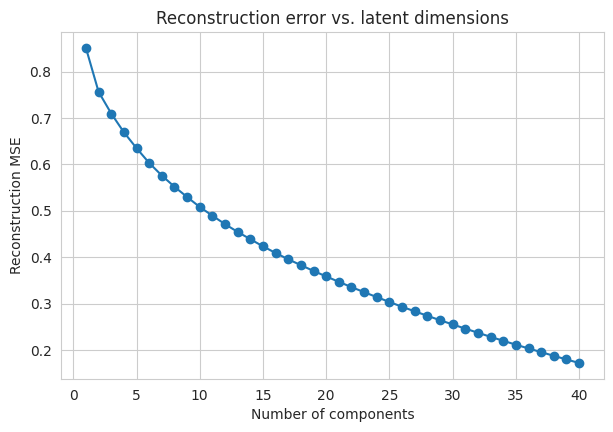

In [ ]:
Zfull = pca.transform(X_scaled)
ks = list(range(1, 41))
errs = []
for k in ks:
    X_rec = Zfull[:, :k] @ pca.components_[:k] + pca.mean_
    errs.append(np.mean((X_scaled - X_rec)**2))

plt.figure(figsize=(7, 4.5))
plt.plot(ks, errs, 'o-')
plt.xlabel('Number of components'); plt.ylabel('Reconstruction MSE')
plt.title('Reconstruction error vs. latent dimensions')
plt.show()

k=  1  accuracy=0.6280 +/- 0.0642
k=  2  accuracy=0.7063 +/- 0.0796
k=  3  accuracy=0.8179 +/- 0.1028
k=  5  accuracy=0.9257 +/- 0.0505
k=  8  accuracy=0.9219 +/- 0.0545
k= 10  accuracy=0.9305 +/- 0.0563
k= 15  accuracy=0.9276 +/- 0.0666
k= 20  accuracy=0.9389 +/- 0.0567
k= 25  accuracy=0.9470 +/- 0.0632
k= 30  accuracy=0.9446 +/- 0.0623
k= 40  accuracy=0.9587 +/- 0.0577
k= 50  accuracy=0.9697 +/- 0.0509
k= 55  accuracy=0.9724 +/- 0.0431


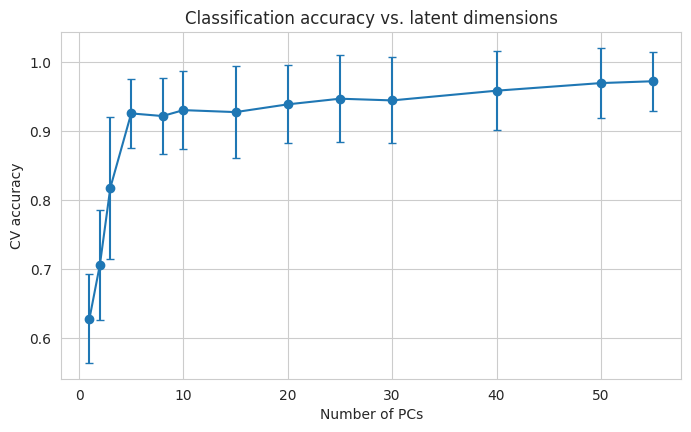

Best k: 55 | accuracy = 0.9724
Smallest k within 0.01 of best: 50


In [ ]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
ks = [1, 2, 3, 5, 8, 10, 15, 20, 25, 30, 40, 50, 55]
means, stds = [], []

for k in ks:
    pipe = make_pipeline(StandardScaler(), PCA(n_components=k, random_state=42),
                         LogisticRegression(max_iter=3000))
    s = cross_val_score(pipe, X.values, y, cv=cv, scoring='accuracy', n_jobs=-1)
    means.append(s.mean()); stds.append(s.std())
    print(f'k={k:>3}  accuracy={s.mean():.4f} +/- {s.std():.4f}')

plt.figure(figsize=(8, 4.5))
plt.errorbar(ks, means, yerr=stds, fmt='o-', capsize=3)
plt.xlabel('Number of PCs'); plt.ylabel('CV accuracy')
plt.title('Classification accuracy vs. latent dimensions')
plt.show()

best_k = ks[int(np.argmax(means))]
parsimonious_k = next(k for k, m in zip(ks, means) if m >= max(means) - 0.01)
print('Best k:', best_k, '| accuracy =', round(max(means), 4))
print('Smallest k within 0.01 of best:', parsimonious_k)

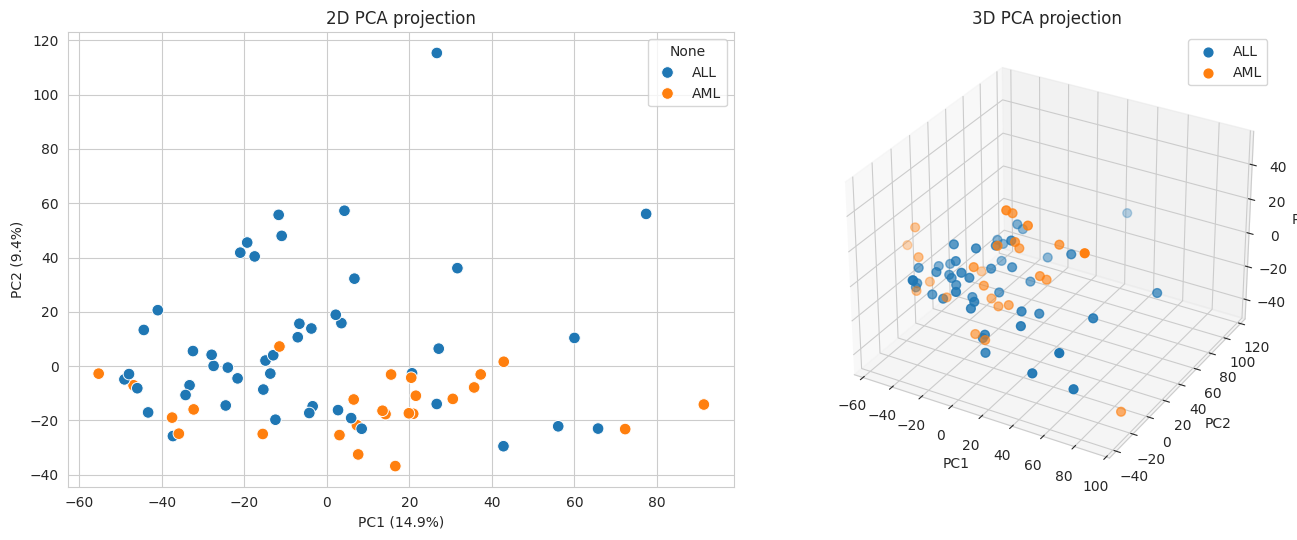

In [ ]:
names = class_names[y]
fig = plt.figure(figsize=(14, 5.5))

ax1 = fig.add_subplot(1, 2, 1)
sns.scatterplot(x=Zfull[:,0], y=Zfull[:,1], hue=names, s=70, ax=ax1)
ax1.set(xlabel=f'PC1 ({evr[0]*100:.1f}%)', ylabel=f'PC2 ({evr[1]*100:.1f}%)', title='2D PCA projection')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for lab in class_names:
    m = names == lab
    ax2.scatter(Zfull[m,0], Zfull[m,1], Zfull[m,2], label=lab, s=40)
ax2.set(xlabel='PC1', ylabel='PC2', zlabel='PC3', title='3D PCA projection')
ax2.legend()
plt.tight_layout(); plt.show()